## Exercitiul 1

Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [N]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1 seconds.


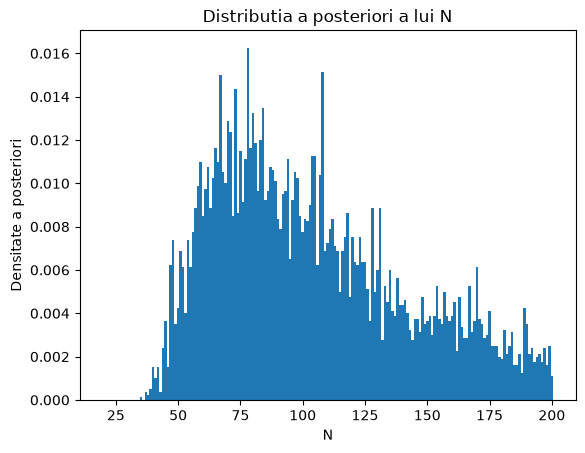

In [5]:
# a)
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

M = 20
n = 15
Y_obs = 4

with pm.Model() as model:
    N = pm.DiscreteUniform('N', lower=20, upper=200)
    pm.HyperGeometric('Y', N=N, k=M, n=n, observed=Y_obs)
    trace = pm.sample(draws=2000, chains=4, random_seed=42)

posterior_N = trace['posterior']['N'].values.flatten()

plt.hist(posterior_N, bins=np.arange(20, 202) - 0.5, density=True)
plt.xlabel('N')
plt.ylabel('Densitate a posteriori')
plt.title('Distributia a posteriori a lui N')
plt.savefig('ex1_posterior_N.png')
plt.show()

In [6]:
# b)
media_N = posterior_N.mean()
mediana_N = np.median(posterior_N)
hdi_N = az.hdi(trace['posterior']['N'], prob=0.95)
hdi_N_low = hdi_N.sel(ci_bound='lower').item()
hdi_N_high = hdi_N.sel(ci_bound='upper').item()
estimare_clasica = M * n / Y_obs

print('Media a posteriori:', media_N)
print('Mediana a posteriori:', mediana_N)
print('HDI 95%:', (hdi_N_low, hdi_N_high))
print(f'Media vs Estimarea clasica: {media_N} vs {estimare_clasica}')

Media a posteriori: 103.73725
Mediana a posteriori: 97.0
HDI 95%: (45.0, 181.0)
Media vs Estimarea clasica: 103.73725 vs 75.0


In [7]:
# c)
prob_N_gt_100 = (trace['posterior']['N'] > 100).mean().item()
print('P(N > 100 | Y = 4):', prob_N_gt_100)

P(N > 100 | Y = 4): 0.465


/home/edward/Facultate/Anul3/Sem1/PMP-2026/.venv/lib/python3.12/site-packages/pytensor/link/numba/dispatch/basic.py:234: UserWarning: Numba will use object mode to run hypergeometric_rv{"(),(),()->()"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [Y_new]


Output()

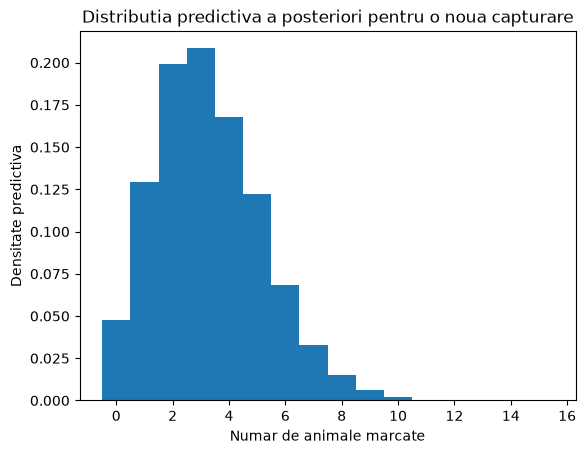

In [8]:
# d)
with model:
    Y_new = pm.HyperGeometric('Y_new', N=N, k=M, n=n)
    ppc = pm.sample_posterior_predictive(trace, var_names=['Y_new'], random_seed=42)

y_new = ppc['posterior_predictive']['Y_new'].values.flatten()

plt.hist(y_new, bins=np.arange(0, 17) - 0.5, density=True)
plt.xlabel('Numar de animale marcate')
plt.ylabel('Densitate predictiva')
plt.title('Distributia predictiva a posteriori pentru o noua capturare')
plt.savefig('ex1_predictiv_Ynew.png')
plt.show()